# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [2]:
# Add code here 🔧
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Load hotel booking data
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv'
df = pd.read_csv(url)

# Preview the data
display(df.head())

# Summary statistics
display(df.describe())

# Check data types and missing values
df.info()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9404 entries, 0 to 9403
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           9404 non-null   object 
 1   is_canceled                     9404 non-null   int64  
 2   lead_time                       9404 non-null   int64  
 3   arrival_date_year               9404 non-null   int64  
 4   arrival_date_month              9404 non-null   object 
 5   arrival_date_week_number        9404 non-null   int64  
 6   arrival_date_day_of_month       9404 non-null   int64  
 7   stays_in_weekend_nights         9404 non-null   int64  
 8   stays_in_week_nights            9404 non-null   int64  
 9   adults                          9404 non-null   int64  
 10  children                        9404 non-null   int64  
 11  babies                          9404 non-null   int64  
 12  meal                            94

### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. The data includes both numeric booking details and categorical information. Some values need checking, including a negative average daily rate, bookings with zero nights, and a booking with 55 adults. The company and agent columns also contain many missing values. These issues should be considered before clustering.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [3]:
# Add code here 🔧
# Remove exact duplicate rows
clean_df = df.drop_duplicates().copy()

# Combine weekday and weekend nights into total stay length
clean_df['total_nights'] = (
    clean_df['stays_in_weekend_nights']
    + clean_df['stays_in_week_nights']
)

# Select five features describing booking behavior
features = [
    'lead_time',
    'total_nights',
    'adr',
    'adults',
    'total_of_special_requests'
]

# Ensure selected features are numeric and remove missing values
clean_df[features] = clean_df[features].apply(
    pd.to_numeric, errors='coerce'
)
clean_df = clean_df.dropna(subset=features)

# Apply practical limits to focus on typical individual bookings
clean_df = clean_df[
    clean_df['lead_time'].between(0, 365)
    & clean_df['total_nights'].between(1, 30)
    & clean_df['adr'].between(0, 500, inclusive='right')
    & clean_df['adults'].between(1, 6)
].copy()

# Correct count-column data types
count_columns = [
    'lead_time', 'total_nights', 'adults',
    'total_of_special_requests'
]
clean_df[count_columns] = clean_df[count_columns].astype(int)
clean_df = clean_df.reset_index(drop=True)

# Standardize selected features for comparable weighting
scaler = StandardScaler()
X_scaled = scaler.fit_transform(clean_df[features])

print(f"Original bookings: {len(df):,}")
print(f"Cleaned bookings: {len(clean_df):,}")
display(clean_df[features].describe())

Original bookings: 9,404
Cleaned bookings: 7,498


,lead_time,total_nights,adr,adults,total_of_special_requests
count,7498.000000,7498.000000,7498.000000,7498.000000,7498.000000
mean,63.930782,4.386636,93.508123,1.829421,0.691518
std,73.481907,3.289348,53.906222,0.465830,0.857880
min,0.000000,1.000000,2.000000,1.000000,0.000000
25%,6.000000,2.000000,48.000000,2.000000,0.000000
50%,38.000000,4.000000,79.000000,2.000000,0.000000
75%,93.000000,7.000000,129.595000,2.000000,1.000000
max,364.000000,29.000000,367.000000,4.000000,5.000000


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected lead time, total nights, average daily rate, adults, and total special requests. These describe how early customers book, their stay length, nightly spending, adult party size, and service requests. I combined weekday and weekend nights into total nights to represent overall stay length.

2. I expect to find groups such as early planners, last minute bookers, longer stay guests, and customers booking higher priced rooms. Party size and special requests may also help distinguish groups with different service needs.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

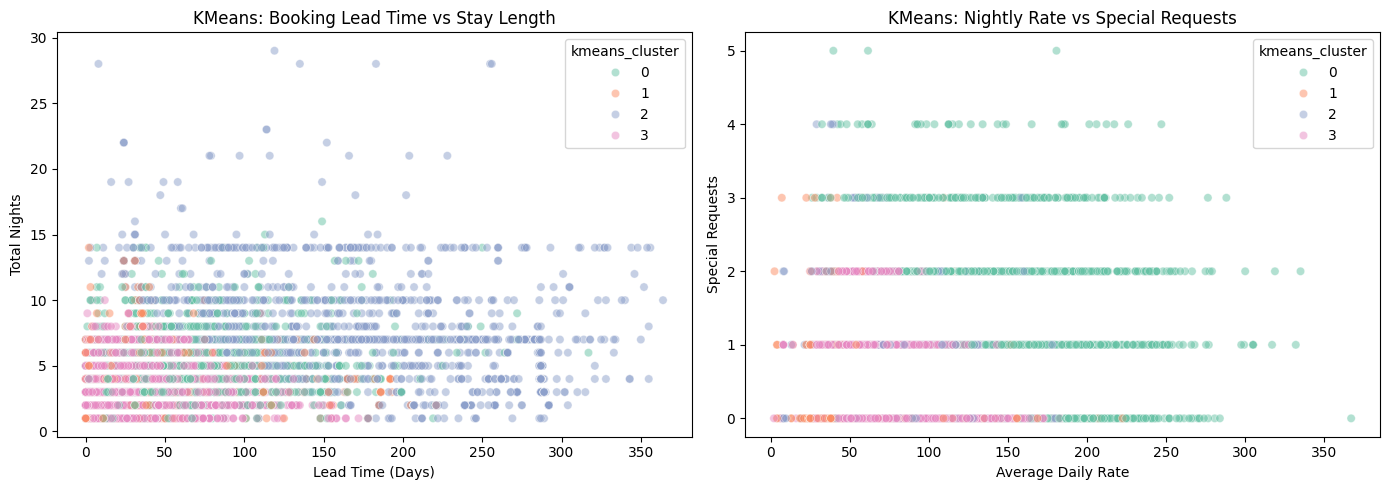

,count
kmeans_cluster,
0,1876
1,1406
2,1564
3,2652


,lead_time,total_nights,adr,adults,total_of_special_requests
kmeans_cluster,,,,,
0,61.25,5.18,155.72,2.09,1.45
1,19.21,2.33,51.15,1.00,0.28
2,167.14,7.75,82.53,1.94,0.50
3,28.67,2.93,78.43,2.02,0.49


In [4]:
# Add code here 🔧
# Fit KMeans using the five standardized features
k = 4
kmeans = KMeans(n_clusters=k, random_state=1, n_init=10)
clean_df['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

# Plot two different pairs of features in original units
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=clean_df,
    x='lead_time', y='total_nights',
    hue='kmeans_cluster',
    palette='Set2', alpha=0.5, ax=axes[0]
)
axes[0].set_title('KMeans: Booking Lead Time vs Stay Length')
axes[0].set_xlabel('Lead Time (Days)')
axes[0].set_ylabel('Total Nights')

sns.scatterplot(
    data=clean_df,
    x='adr', y='total_of_special_requests',
    hue='kmeans_cluster',
    palette='Set2', alpha=0.5, ax=axes[1]
)
axes[1].set_title('KMeans: Nightly Rate vs Special Requests')
axes[1].set_xlabel('Average Daily Rate')
axes[1].set_ylabel('Special Requests')

plt.tight_layout()
plt.show()

# Display cluster sizes and feature averages
display(clean_df['kmeans_cluster'].value_counts().sort_index())

kmeans_summary = clean_df.groupby('kmeans_cluster')[features].mean()
display(kmeans_summary.round(2))

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose k = 4 as a starting point because it provides a manageable number of segments for targeted marketing while allowing differences across five booking features. This is an exploratory choice, rather than a claim that four is the optimal number of clusters.

2. Cluster 0 represents higher rate bookings with more special requests. These bookings average about 156 per night, five nights, and 1.45 requests.

Cluster 1 represents solo adult bookings with shorter stays and lower nightly rates. They average one adult, about two nights, and a nightly rate of 51.

Cluster 2 represents early planners with longer stays. Their most prominent features are an average lead time of 167 days and a stay of nearly eight nights.

Cluster 3 represents shorter stays booked closer to arrival, typically for two adults. They average about three nights, a lead time of 29 days, and a nightly rate of 78.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

,Cluster 0 probability,Cluster 1 probability,Cluster 2 probability,Cluster 3 probability
0,1.0,7.534681e-09,0.000000,0.000000
1,1.0,9.792064e-09,0.000000,0.000000
2,0.0,3.239561e-06,0.999997,0.000000
3,0.0,2.393232e-09,0.000153,0.999847
4,0.0,2.956848e-06,0.999997,0.000000


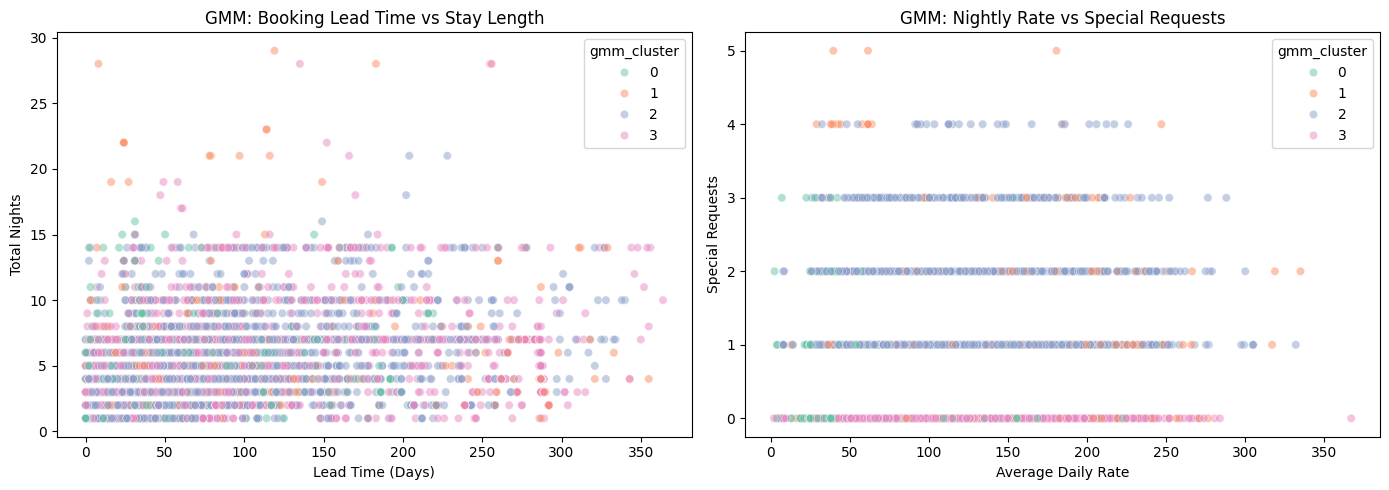

,count
gmm_cluster,
0,1476
1,356
2,2999
3,2667


,lead_time,total_nights,adr,adults,total_of_special_requests
gmm_cluster,,,,,
0,23.45,2.69,53.10,1.00,0.32
1,109.65,5.94,128.20,2.55,1.00
2,68.54,4.72,106.99,2.00,1.45
3,75.06,4.75,96.08,2.00,0.00


In [5]:
# Add your code here
# Fit GMM with the same four groups and standardized features
gmm = GaussianMixture(n_components=k, random_state=1, n_init=10)
gmm.fit(X_scaled)

# Soft clustering: probability of belonging to each group
gmm_probabilities = gmm.predict_proba(X_scaled)

probability_df = pd.DataFrame(
    gmm_probabilities,
    columns=[f'Cluster {i} probability' for i in range(k)]
)
display(probability_df.head())

# Use the highest probability group for plots and summaries
clean_df['gmm_cluster'] = gmm_probabilities.argmax(axis=1)

# Plot two different pairs of features
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=clean_df,
    x='lead_time', y='total_nights',
    hue='gmm_cluster',
    palette='Set2', alpha=0.5, ax=axes[0]
)
axes[0].set_title('GMM: Booking Lead Time vs Stay Length')
axes[0].set_xlabel('Lead Time (Days)')
axes[0].set_ylabel('Total Nights')

sns.scatterplot(
    data=clean_df,
    x='adr', y='total_of_special_requests',
    hue='gmm_cluster',
    palette='Set2', alpha=0.5, ax=axes[1]
)
axes[1].set_title('GMM: Nightly Rate vs Special Requests')
axes[1].set_xlabel('Average Daily Rate')
axes[1].set_ylabel('Special Requests')

plt.tight_layout()
plt.show()

# Display cluster sizes and feature averages
display(clean_df['gmm_cluster'].value_counts().sort_index())

gmm_summary = clean_df.groupby('gmm_cluster')[features].mean()
display(gmm_summary.round(2))

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. Both models identified solo adult bookings with shorter stays and lower rates. However, their other groups differed. KMeans separated early planners with longer stays and higher rate bookings with more requests. GMM more strongly separated bookings by adult party size and special requests. For example, GMM clusters 2 and 3 both averaged two adults, but cluster 2 averaged 1.45 requests while cluster 3 had none. Cluster numbers are labels and do not correspond directly between models.

2. GMM could help a hotel identify bookings that share characteristics with multiple segments. Membership probabilities could guide whether to offer a longer stay promotion, an upgraded room, or additional services when a booking does not fit clearly into one group. These probabilities describe membership under the model - they do not directly predict whether a customer will accept an offer.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [6]:
# Add code here 🔧
import numpy as np

# Use the same WCSS definition for both models:
# sum of squared distances to each assigned cluster's mean
def calculate_wcss(X, labels):
    wcss = 0
    for cluster in np.unique(labels):
        points = X[labels == cluster]
        center = points.mean(axis=0)
        wcss += ((points - center) ** 2).sum()
    return wcss

results = []

for name, column in [
    ('KMeans', 'kmeans_cluster'),
    ('GMM', 'gmm_cluster')
]:
    labels = clean_df[column].to_numpy()

    results.append({
        'Model': name,
        'WCSS': calculate_wcss(X_scaled, labels),
        'Silhouette': silhouette_score(X_scaled, labels),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, labels)
    })

evaluation = pd.DataFrame(results).set_index('Model')
display(evaluation.round(4))

,WCSS,Silhouette,Davies-Bouldin
Model,,,
KMeans,19194.6871,0.2760,1.3486
GMM,24389.6085,0.2427,2.4050


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. KMeans performed better on all three metrics. Its WCSS was lower, at 19,194.69 compared with 24,389.61 for GMM. Its silhouette score was higher, at 0.2760 compared with 0.2427, and its Davies-Bouldin index was lower, at 1.3486 compared with 2.4050. These results indicate more compact and better separated groups under these measures, although the silhouette scores suggest substantial overlap remains.

5.3. I would recommend KMeans for this analysis because it performed better on the evaluation metrics and provides straightforward segments for marketing campaigns. GMM would be useful if the business specifically needed membership probabilities for bookings that share characteristics with multiple groups. Before using either model, I would also check whether the segments are stable and useful for actual business decisions.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [7]:
# Add code here 🔧
# Summarize the recommended KMeans model in original units
business_summary = clean_df.groupby('kmeans_cluster')[features].mean()

# Include the number of bookings in each group
business_summary['booking_count'] = (
    clean_df.groupby('kmeans_cluster').size()
)

# Sort by average nightly rate
display(business_summary.sort_values('adr').round(2))

,lead_time,total_nights,adr,adults,total_of_special_requests,booking_count
kmeans_cluster,,,,,,
1,19.21,2.33,51.15,1.00,0.28,1406
3,28.67,2.93,78.43,2.02,0.49,2652
2,167.14,7.75,82.53,1.94,0.50,1564
0,61.25,5.18,155.72,2.09,1.45,1876


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. The four segments represent different booking behaviors. Cluster 0 contains higher rate bookings with more special requests. Cluster 1 contains solo adult bookings with shorter stays and lower rates. Cluster 2 contains customers who book far in advance and stay longer. Cluster 3 contains mostly two adult bookings for shorter stays, booked closer to arrival.

2. For cluster 0, the hotel could offer room upgrades and personalized services. For cluster 1, it could promote affordable short stay packages. For cluster 2, early booking offers and extended stay packages could be relevant. For cluster 3, it could test short break packages and offers closer to arrival. The hotel should test these promotions to determine whether they improve bookings and profitability.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The most challenging part was interpreting the groups without predefined correct answers. Choosing features, scaling them, and selecting the number of clusters all affect the results. The evaluation scores helped compare models, but I also needed to examine the cluster averages to understand whether the groups made business sense.

2. I would use clustering when the goal is to discover groups in data without a known target label. For example, a hotel could explore booking segments before creating marketing campaigns. Supervised models would be more appropriate when predicting a known outcome, such as whether a booking will be canceled.

3. Clustering helps a manager identify groups of bookings with similar characteristics. Instead of sending every customer the same promotion, the hotel can test offers suited to different booking patterns, such as longer stays or bookings made close to arrival. This gives the business a practical starting point for more targeted marketing and service planning.

4. This assignment supports my learning outcomes by giving me practice comparing models in Python, evaluating performance metrics, and communicating results through visualizations. Although clustering does not forecast investment returns, comparing KMeans and GMM helped me assess model strengths and limitations. These skills also apply to financial analysis, where I could group investments with similar characteristics and explain the patterns to investment decision makers without overstating what the results show.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"